# Flow of study
* Linear Regression
* Logistic Regression
* KNN
* Decision Trees
* Naive Bayes
* SVM
* Random Forest
* Gradient Boosting (XGBoost, LightGBM)
* K-Means
* PCA
* Neural Networks

# 📊 Linear Regression

## 1. What is Linear Regression?

**Linear Regression** is a **Supervised Machine Learning algorithm** that is used to predict a **continuous numeric value**.

It finds the **linear relationship** between:
- Independent variable (Feature) → `X`
- Dependent variable (Target) → `Y`

### Example:
| Feature (X)          | Target (Y) |
|----------------------|------------|
| Years of Experience  | Salary     |

If experience increases, salary usually increases.  
This straight-line relationship is called **Linear Regression**.


## 2. Types of Linear Regression

### ✅ Simple Linear Regression
- Uses **one independent variable**
- Predicts one output

**Formula:**
y = mx + c


### ✅ Multiple Linear Regression
- Uses **multiple independent variables**

**Formula:**
y = m1x1 + m2x2 + m3x3 + c

## 3. Linear Regression Equation

\[
y = mx + c
\]

Where:
- `y` → Predicted value
- `x` → Input feature
- `m` → Slope
- `c` → Intercept


## 4. Assumptions of Linear Regression

Linear Regression works best when:

1. Linear relationship exists between X and Y  
2. No multicollinearity between features  
3. Errors have constant variance (Homoscedasticity)  
4. Observations are independent  
5. Errors are normally distributed  


## 5. When to Use Linear Regression

Use when:
- Output is **continuous**
- Data shows a **linear trend**
- Prediction of numerical values is required

Do NOT use when:
- Output is categorical
- Relationship is non-linear


## 6. Disadvantages of Linear Regression

- Cannot handle non-linear data
- Sensitive to outliers
- Assumes strong assumptions


## 7. Real-world Applications

- House price prediction
- Salary prediction
- Sales forecasting
- Weather estimation
- Stock price trends


## ✅ 1. Underfitting
# What it means:
The model is too simple to understand the pattern in the data.
It fails to learn the relationship between input (X) and output (Y).

How it looks:

* Poor performance on training data
* Poor performance on test data

Example:

Trying to fit a straight line on highly curved data.

Causes:

* Model is too simple
* Too few features
* Not enough training time

How to fix:

✅ Use a more complex model
✅ Add more features
✅ Train longer

## ✅ 2. Overfitting
# What it means:
The model learns the training data too well, including noise and random details.
It performs excellent on training data but fails on new/unseen data.

How it looks:
* Very high accuracy on training set
* Very poor accuracy on test set

Example:
A model that remembers answers instead of learning patterns.

Causes:

* Model is too complex
* Too many features
* Very small dataset

How to fix:

✅ Use a simpler model
✅ Use regularization (L1/L2)
✅ Use cross-validation
✅ Increase training data

| Feature           | Underfitting   | Overfitting   |
| ----------------- | -------------- | ------------- |
| Model Complexity  | Too simple     | Too complex   |
| Training Accuracy | Low            | Very high     |
| Test Accuracy     | Low            | Low           |
| Goal              | Learn patterns | Memorize data |


## Implementing Simple Linear Regression

In [60]:
import pandas as pd
import numpy as np

In [61]:
df = pd.read_csv('Salary.csv')
df.head()

,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891


In [62]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  35 non-null     float64
 1   Salary           35 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 692.0 bytes


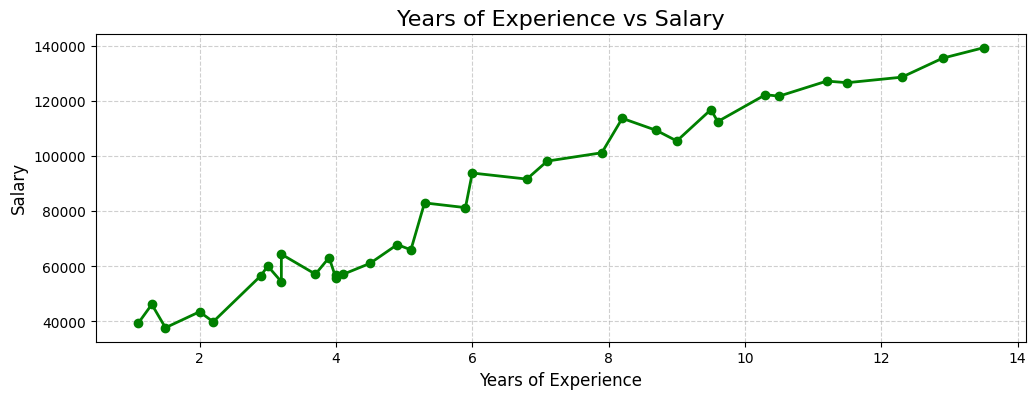

' \n\n“If experience increases, salary usually increases. \nThis straight-line pattern is called a linear relationship, \nand predicting values from it is called Linear Regression.” \n\n'

In [63]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))  # size of the graph

plt.plot(
    df['YearsExperience'],
    df['Salary'],
    color='green',
    marker='o',
    linestyle='-',
    linewidth=2,
    markersize=6
)

plt.title("Years of Experience vs Salary", fontsize=16)
plt.xlabel("Years of Experience", fontsize=12)
plt.ylabel("Salary", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

''' 

“If experience increases, salary usually increases. 
This straight-line pattern is called a linear relationship, 
and predicting values from it is called Linear Regression.” 

'''

In [64]:
df.describe()

,YearsExperience,Salary
count,35.000000,35.000000
mean,6.308571,83945.600000
std,3.618610,32162.673003
min,1.100000,37731.000000
25%,3.450000,57019.000000
50%,5.300000,81363.000000
75%,9.250000,113223.500000
max,13.500000,139465.000000


In [65]:
df.isnull().sum()

YearsExperience    0
Salary             0
dtype: int64

In [66]:
# Defining feature and target
X = df[['YearsExperience']]
y = df['Salary']

In [67]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [68]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [69]:
model.fit(X_train, y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [70]:
y_pred = model.predict(X_test)
y_pred

array([110877.79583392,  64678.96421127, 104033.52448241,  90344.98177941,
        71523.23556278, 119433.1350233 ,  80934.10867109,  63823.43029234,
        56979.15894083,  73234.30340065,  61256.82853552])

In [71]:
from sklearn.metrics import r2_score
print("R2 score:", r2_score(y_test, y_pred))

R2 score: 0.9171426108885095


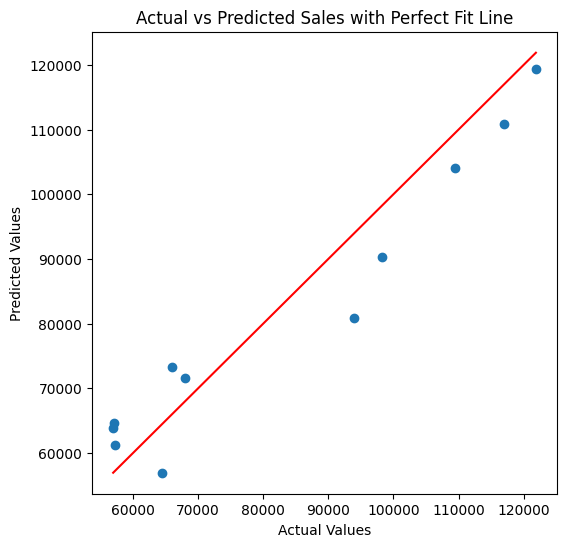

In [72]:
plt.figure(figsize=(6,6))

# Scatter plot
plt.scatter(y_test, y_pred)

# Perfect prediction line (straight line)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot([min_val, max_val], [min_val, max_val], 'r')

# Labels and title
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Sales with Perfect Fit Line")

plt.show()


In [73]:
# Take user input
years = float(input("Enter Years of Experience: "))
# Convert to DataFrame (same format used in training)
input_data = pd.DataFrame({'YearsExperience': [years]})
# Predict
prediction = model.predict(input_data)
# Show result
print(f"Predicted Salary: ₹{prediction[0]:,.2f}")

Enter Years of Experience:  3


Predicted Salary: ₹55,268.09


## Implementing Multiple Linear Regression

In [74]:
data = pd.read_csv('Student_Marks.csv')
data.head()

,number_courses,time_study,Marks
0,3,4.508,19.202
1,4,0.096,7.734
2,4,3.133,13.811
3,6,7.909,53.018
4,8,7.811,55.299


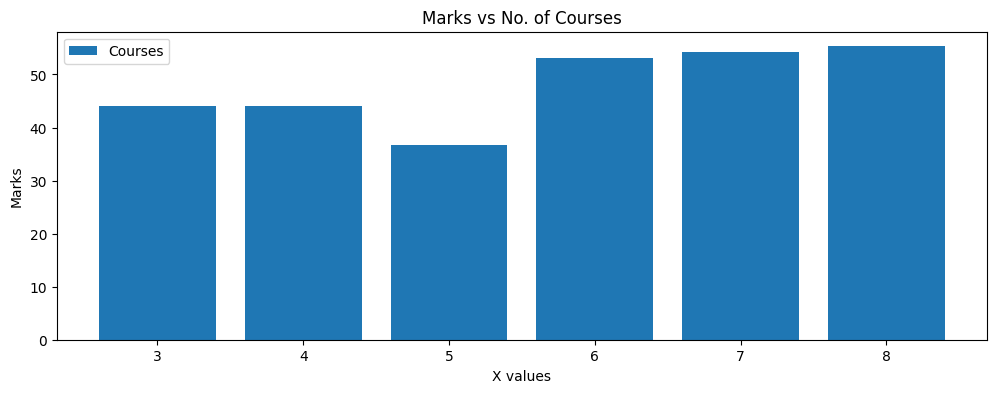

In [75]:
plt.figure(figsize=(12, 4))
plt.bar(data['number_courses'], data['Marks'], label='Courses')
plt.xlabel("X values")
plt.ylabel("Marks")
plt.legend()
plt.title("Marks vs No. of Courses")
plt.show()


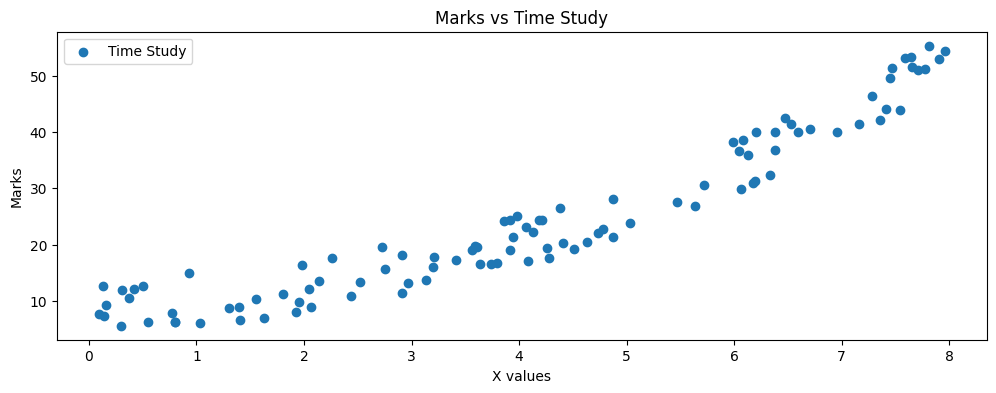

In [76]:
plt.figure(figsize=(12, 4))
plt.scatter(data['time_study'], data['Marks'], label='Time Study')
plt.xlabel("X values")
plt.ylabel("Marks")
plt.legend()
plt.title("Marks vs Time Study")
plt.show()

In [77]:
data.isnull().sum()

number_courses    0
time_study        0
Marks             0
dtype: int64

In [78]:
X = data[['number_courses','time_study']]
y = data['Marks']

In [79]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [80]:
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [81]:
y_pred = model.predict(X_test)
y_pred

array([19.2023582 , 38.09765401, 20.14982671,  9.38493504, 10.72280511,
       45.32451345, 13.13986283, 48.1912327 , 37.38033252, 22.3298968 ,
       44.98594477, 28.44262235,  7.09959647, 39.07686333, 28.22097089,
       49.32278747, 36.03556961, 39.66299991, 28.41141577,  8.65489633,
       21.50778884, 11.82790921,  8.78501278, 23.19058619, 25.07916459,
       22.92185775,  1.12649917,  0.07429642, 31.13797254, 22.99116375])

In [82]:
print("R2 score: ",r2_score(y_test, y_pred))

R2 score:  0.9417542675032118


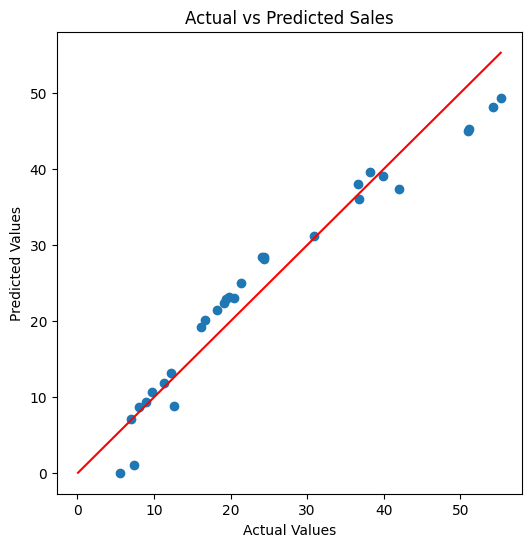

In [83]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred)
# Perfect prediction line (straight line)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot([min_val, max_val], [min_val, max_val], 'r')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Sales")
plt.show()


In [84]:
# Take user input
courses = float(input("Enter number of courses: "))
time = float(input("Enter time of study: "))
# Convert to DataFrame (same format used in training)
input_data = pd.DataFrame({'number_courses': [courses], 'time_study': [time]})
# Predict
prediction = model.predict(input_data)
# Show result
print(f"Predicted Marks: {prediction[0]:,.2f}")

Enter number of courses:  5
Enter time of study:  45


Predicted Marks: 240.35
